# Intro to MatPlotLib

In [44]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


## What is Matplotlib?
- Matplotlib lis a comprehensive library for creating static, and interactive visualisations in Python
- It provides a MATLAB-like interface for plotting
- It is essential for data visualisation, data analysis, and scientific computing
- Also works seamlessly with packages / libraries like NumPy and Pandas

In [72]:
from typing import Any
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Displays plots inline for Jupyter notebooks wihtout you having to manually trigger it
%matplotlib inline

# This sets the style of the plot so it looks better
plt.style.use("default") # Also have the option of using "seaborn", "ggplot", etc.

## 1. Matplotlib Architecture: Figure and Axes
### Key Concepts:
- Figure: This is the top-level container (essentially the entire window or page)
- Axes: This is the actual plot area (where data is drawn)
- Axis: This is the actual axes of the graph (x-axis, y-axis)
- It can be useful to think of Figure as a canvas, and Axes as individual paintings on that canvas


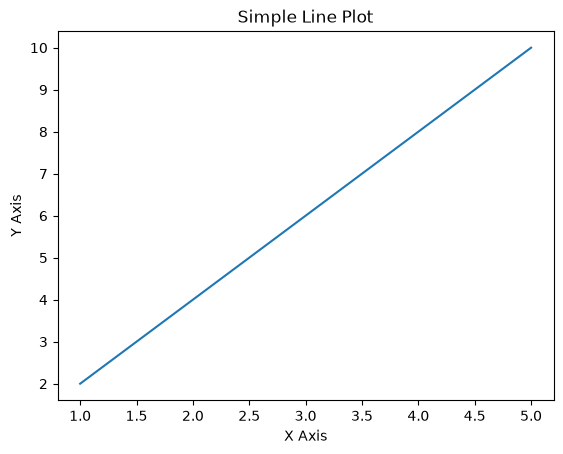

In [46]:
# Method 1 to plot graphs: Pyplot approach (quick and simple)
x = [1,2,3,4,5]
y = [2,4,6,8,10]

plt.plot(x, y)
plt.xlabel("X Axis")
plt.ylabel("Y Axis")
plt.title("Simple Line Plot")
plt.show() # With "%matplotlib inline" this isn't strictly necessary, but it is good practice to include it anyway

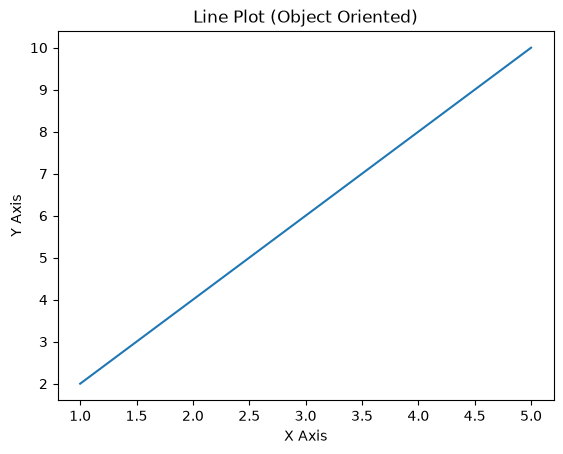

In [47]:
# Method 2 to plot graphs: Object Oriented approach (more control, recommended for complex plots)
fig, ax = plt.subplots() # Creates a figure and axes object
ax.plot(x, y)
ax.set_xlabel("X Axis")
ax.set_ylabel("Y Axis")
ax.set_title("Line Plot (Object Oriented)")
plt.show()

# The OOP approach gives you more control and is better for multiple plots

## 2. Basic Line Plots

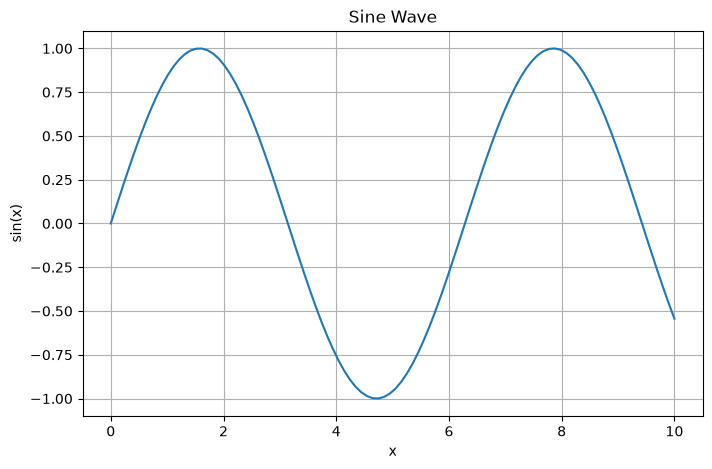

In [48]:
# Create some sample data
x = np.linspace(0, 10, 100) # Creates 100 data points from 0 to 10
y = np.sin(x)

# Simple line plot
fig, ax = plt.subplots()
fig.set_size_inches(8, 5)
ax.plot(x, y)
ax.set_xlabel("x")
ax.set_ylabel("sin(x)")
ax.set_title("Sine Wave")
ax.grid(True)
plt.show()

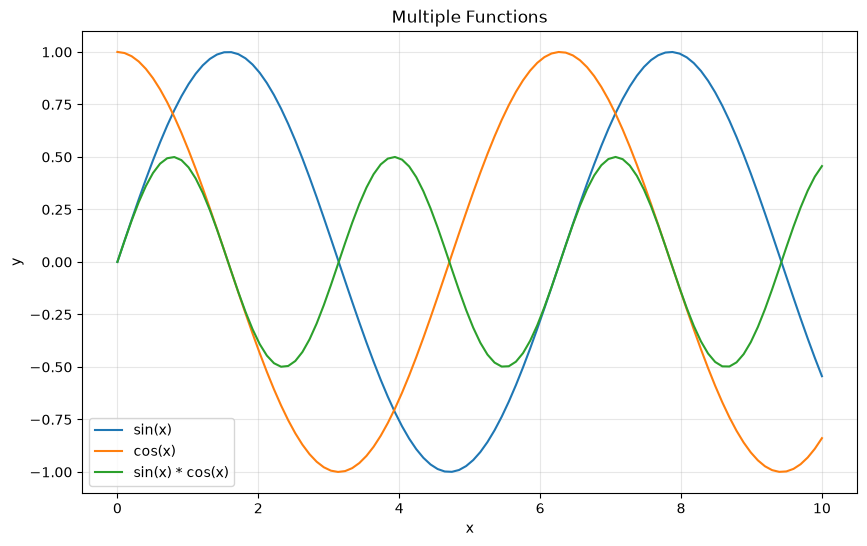

In [49]:
# Multiple lines on the same plot
x = np.linspace(0, 10, 100)
y1 = np.sin(x)
y2 = np.cos(x)
y3 = np.sin(x) * np.cos(x)
labels = ["sin(x)", "cos(x)", "sin(x) * cos(x)"]
Y = np.column_stack([y1, y2, y3]) # Necessary in order to plot 3 different lines using one plot call

fig, ax = plt.subplots()
fig.set_size_inches(10, 6)
ax.plot(x, Y, label=labels) # Since the label field is filled with an iterable, there is a one-to-one correspondence between "labels" and the 3 line plots
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Multiple Functions")
ax.legend() # Show legend for labels
ax.grid(True, alpha=0.3) # Alpha channel controls transparency
plt.show()


## 3. Customising Plots: Colours, Styles and Markers

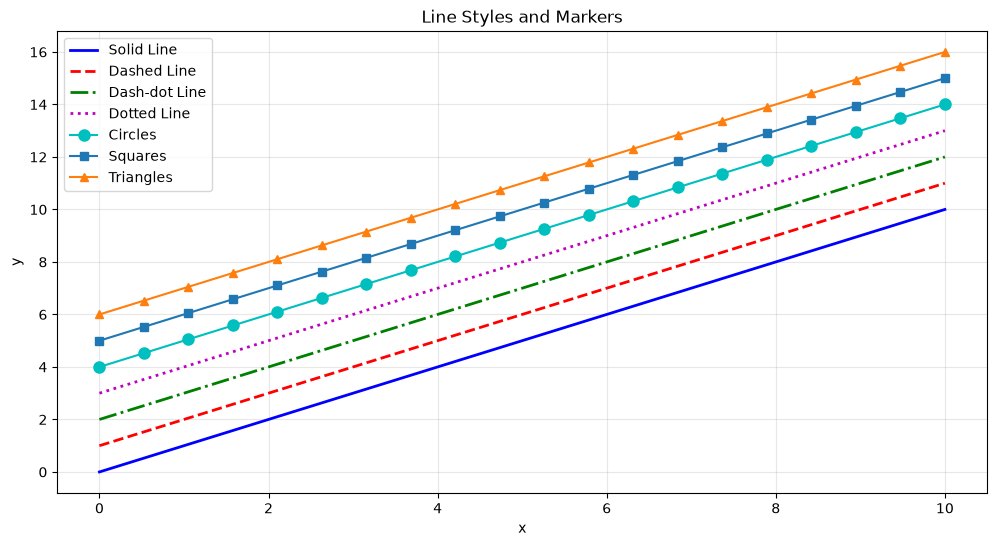

In [50]:
x = np.linspace(0, 10, 20)

# Different line styles and markers
fig, ax = plt.subplots()
fig.set_size_inches(12, 6)

ax.plot(x, x, "b-", label="Solid Line", linewidth=2)
ax.plot(x, x+1, "r--", label="Dashed Line", linewidth=2)
ax.plot(x, x+2, "g-.", label="Dash-dot Line", linewidth=2)
ax.plot(x, x+3, "m:", label="Dotted Line", linewidth=2)
ax.plot(x, x+4, "co-", label="Circles", markersize=8)
ax.plot(x, x+5, "s-", label="Squares", markersize=6)
ax.plot(x, x+6, "^-", label="Triangles", markersize=6)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Line Styles and Markers")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

# Common format string: "[colour][marker][line]"
# Colours: b (blue), r (red), g (green), c (cyan), m (magenta), y (yellow), k (black)
# Markers: o (circle), s (square), ^ (triangle), * (star), + (plus), x (x)
# Lines: - (solid), -- (dashed), -. (dash-dot), : (dotted)

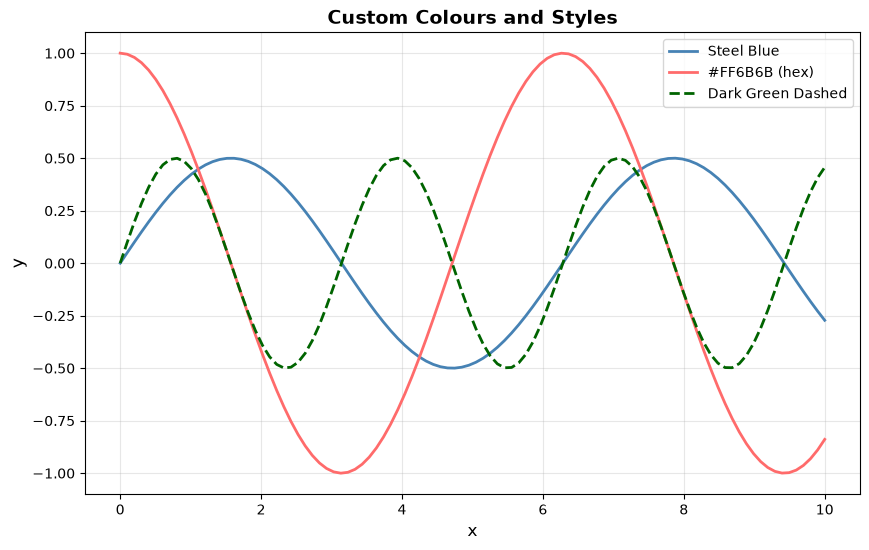

In [51]:
# Using colour names and hex codes
x = np.linspace(0, 10, 100)
fig, ax = plt.subplots(figsize=(10,6))
y1 = np.sin(x)*0.5
y2 = np.cos(x)
y3 = np.sin(x) * np.cos(x)
Y = [y1, y2, y3]
labels = ["Steel Blue", "#FF6B6B (hex)", "Dark Green Dashed"]
colours = ["steelblue", "#FF6B6B", "darkgreen"]
linewidths = [2, 2, 2]
linestyles = ["-", "-", "--"]

for y, label, colour, linestyle, linewidth in zip(Y, labels, colours, linestyles, linewidths):
    ax.plot(x, y, label=label, color=colour, linestyle=linestyle, linewidth=linewidth)

ax.set_xlabel("x",fontsize=12)
ax.set_ylabel("y", fontsize=12)
ax.set_title("Custom Colours and Styles", fontsize=14, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.show()

## 4. Scatter Plots

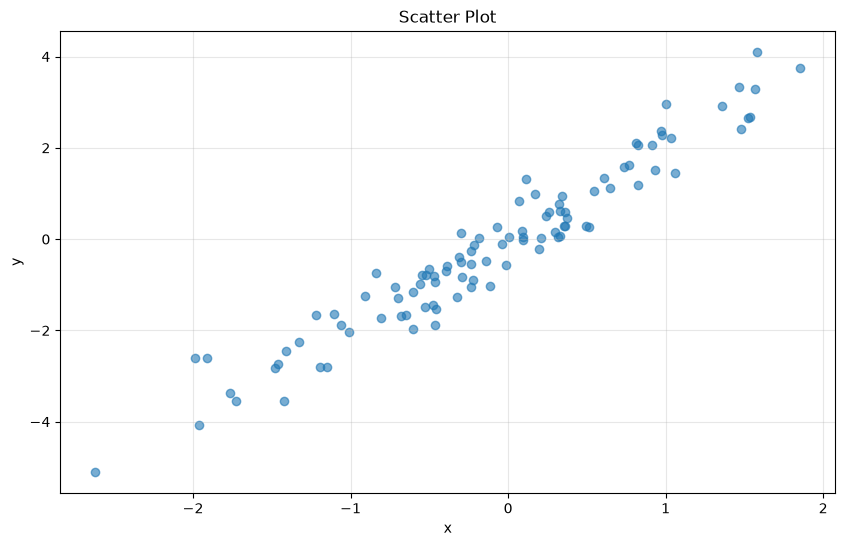

In [52]:
# Generate random sample data
np.random.seed(42)
x = np.random.randn(100) # Generates 100 random numbers
y = 2*x + np.random.randn(100)*0.5 # Creates a linear relationship with some noise

# Basic scatter plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(x, y, alpha=0.6) # Translucency allows for you to see datapoints intersecting with eachother
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Scatter Plot")
ax.grid(True, alpha=0.3)
plt.show()

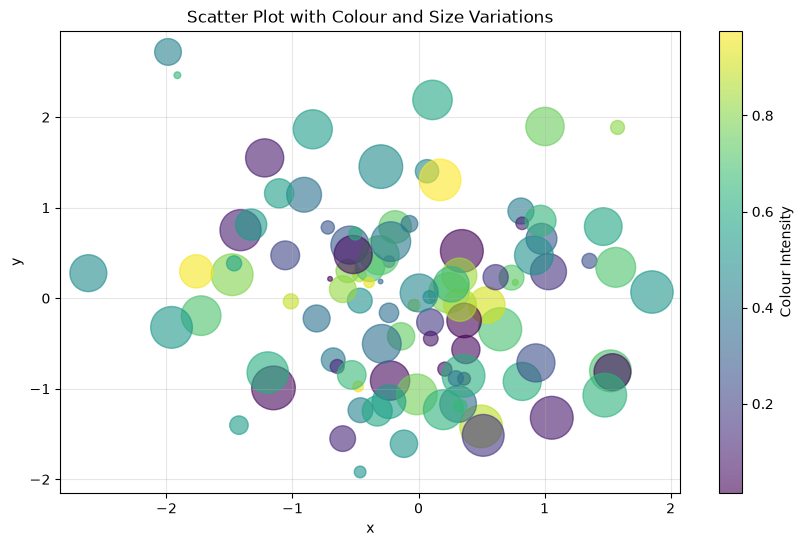

In [53]:
# Scatter plot with different colours and sizes
np.random.seed(42)
x = np.random.randn(100)
y = np.random.randn(100)
colours = np.random.rand(100) # Generates a random number between 0 and 1 for every x-y point which then corresponds to a colour in the colourmap
sizes = 1000 * np.random.rand(100) # Generates random sizes for each data point

fig, ax = plt.subplots(figsize=(10,6))
scatter = ax.scatter(x, y, c=colours, s=sizes, alpha=0.6, cmap="viridis")
fig.colorbar(scatter, label="Colour Intensity") # Necessary to see the colour bar on the right
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Scatter Plot with Colour and Size Variations")
ax.grid(True, alpha=0.3)
plt.show()

# Popular colourmaps: "viridis", "plasma", "coolwarm", "RdYlBu", "Set1"

## 5. Bar Charts

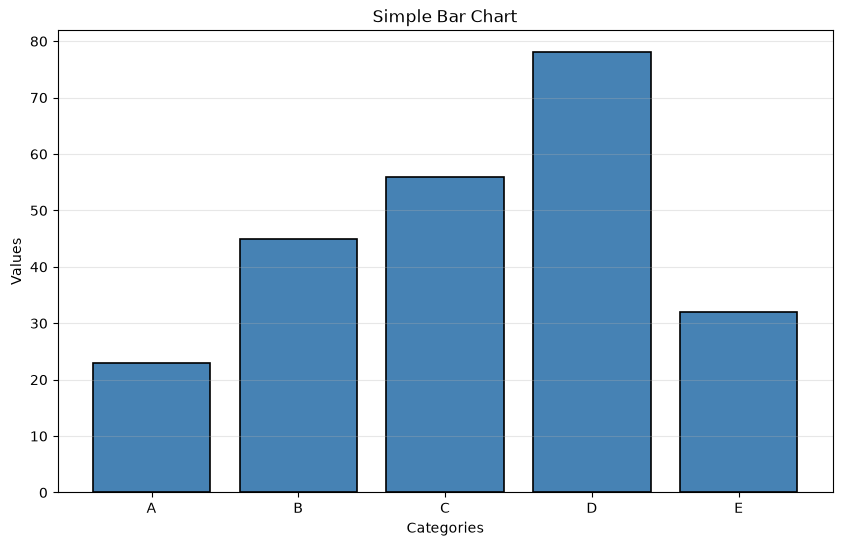

In [54]:
# Simple bar chart
categories = ["A", "B", "C", "D", "E"]
values = [23, 45, 56, 78, 32]

fig, ax = plt.subplots(figsize=(10,6))

ax.bar(categories, values, color="steelblue", edgecolor="black", linewidth=1.2) # Alternatively use "plt.barh()" to have the bars come out horizontally
ax.set_xlabel("Categories")
ax.set_ylabel("Values")
ax.set_title("Simple Bar Chart")
ax.grid(True, alpha=0.3, axis="y") # Only show horizontal grid lines
plt.show()

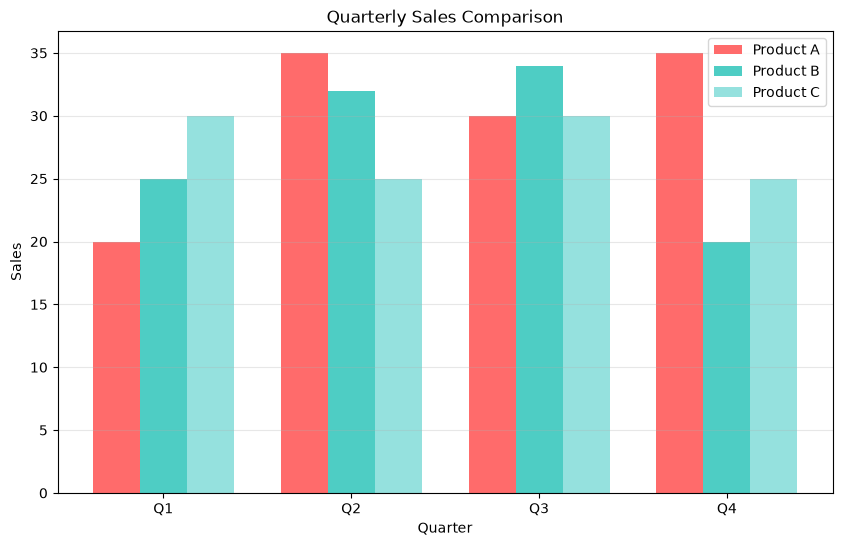

In [55]:
# Grouped bar chart
categories = ["Q1", "Q2", "Q3", "Q4"]
product_a = [20, 35, 30 ,35]
product_b = [25, 32, 34, 20]
product_c = [30, 25, 30, 25]

x = np.arange(len(categories)) # Creates a NumPy array of evenly spaced numbers. For this specific example array([0, 1, 2, 3])
width = 0.25 # Width of the bars
fig, ax = plt.subplots(figsize=(10, 6))
# ax.bar(x, height, width, ...) parameters:
# product_a: height values for "Product A" bars
# width: width of each bar (0.25)
# label: text for the legend
# color: bar fill colour (hex code)

# x - width: x-position (shift left by one bar width to position first group)
ax.bar(x - width, product_a, width, label="Product A", color="#FF6B6B")
# x: centre position for second group (no shift)
ax.bar(x, product_b, width, label="Product B", color="#4ECDC4")
# x + width: x-position (shift right by one bar width to position third group)
ax.bar(x + width, product_c, width, label="Product C", color="#95E1DE")
ax.set_xlabel("Quarter")
ax.set_ylabel("Sales")
ax.set_title("Quarterly Sales Comparison")
ax.set_xticks(x, categories)
ax.legend()
ax.grid(True, alpha=0.3, axis="y")
plt.show()

## 6. Histograms
Histograms show the distribution of numerical data by grouping values into bins.

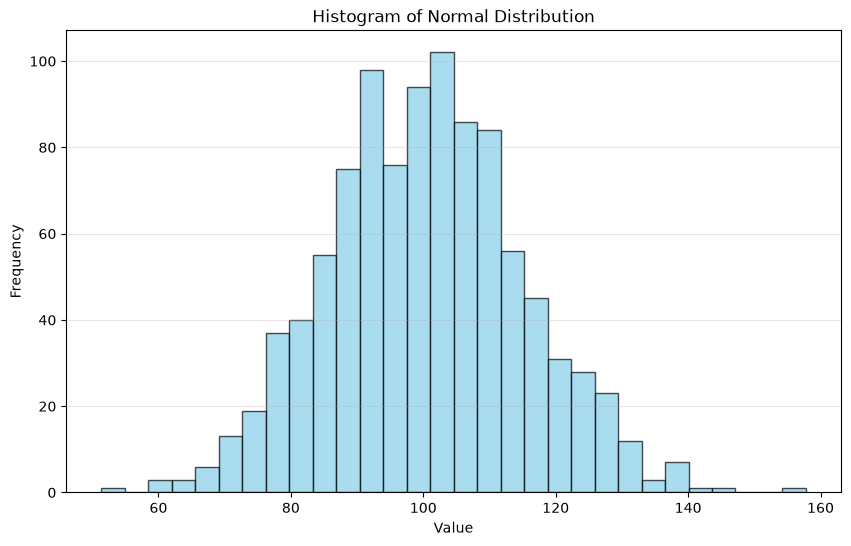

In [56]:
np.random.seed(42)
data = np.random.normal(100, 15, 1000) # Mean=100, Std=15, 1000 points

# Basic histogram
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(data, bins=30, color="skyblue", edgecolor="black", alpha=0.7)
ax.set_xlabel("Value")
ax.set_ylabel("Frequency")
ax.set_title("Histogram of Normal Distribution")
ax.grid(True, alpha=0.3, axis="y")
plt.show() # Use plt.show() even if you do fig, ax = plt.subplots() as it handles things that fig.show() can't "UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown - fig.show()"

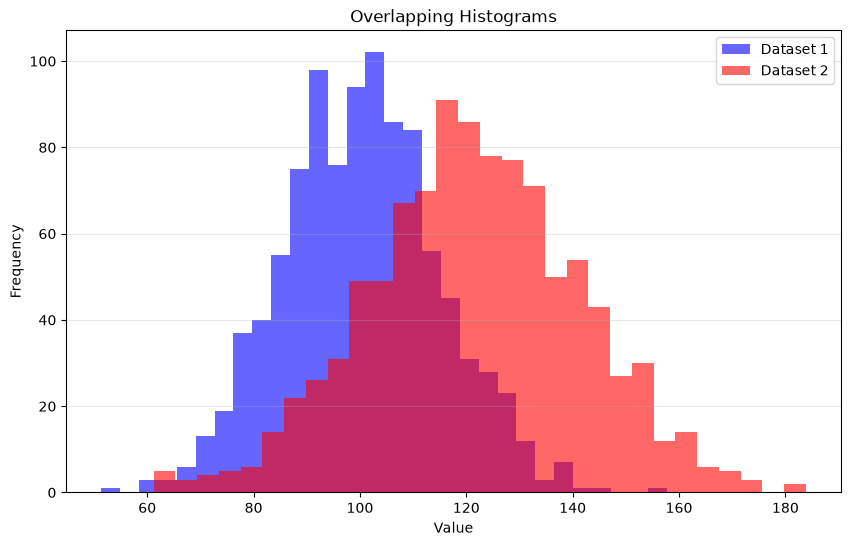

In [57]:
# Multiple histograms on the same plot
np.random.seed(42)
data1 = np.random.normal(100, 15, 1000)
data2 = np.random.normal(120, 20, 1000)

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(data1, bins=30, alpha=0.6, label="Dataset 1", color="blue") # Alpha channel allows for the overlap to be shown in a colour mix of the 2 datasets
ax.hist(data2, bins=30, alpha=0.6, label="Dataset 2", color="red")
ax.set_xlabel("Value")
ax.set_ylabel("Frequency")
ax.set_title("Overlapping Histograms")
ax.legend()
ax.grid(True, alpha=0.3, axis="y")
plt.show()

## 7. Subplots: Multiple Plots in One Figure
Subplots allow you to create multiple plots in one single figure, great for comparing different visualisations

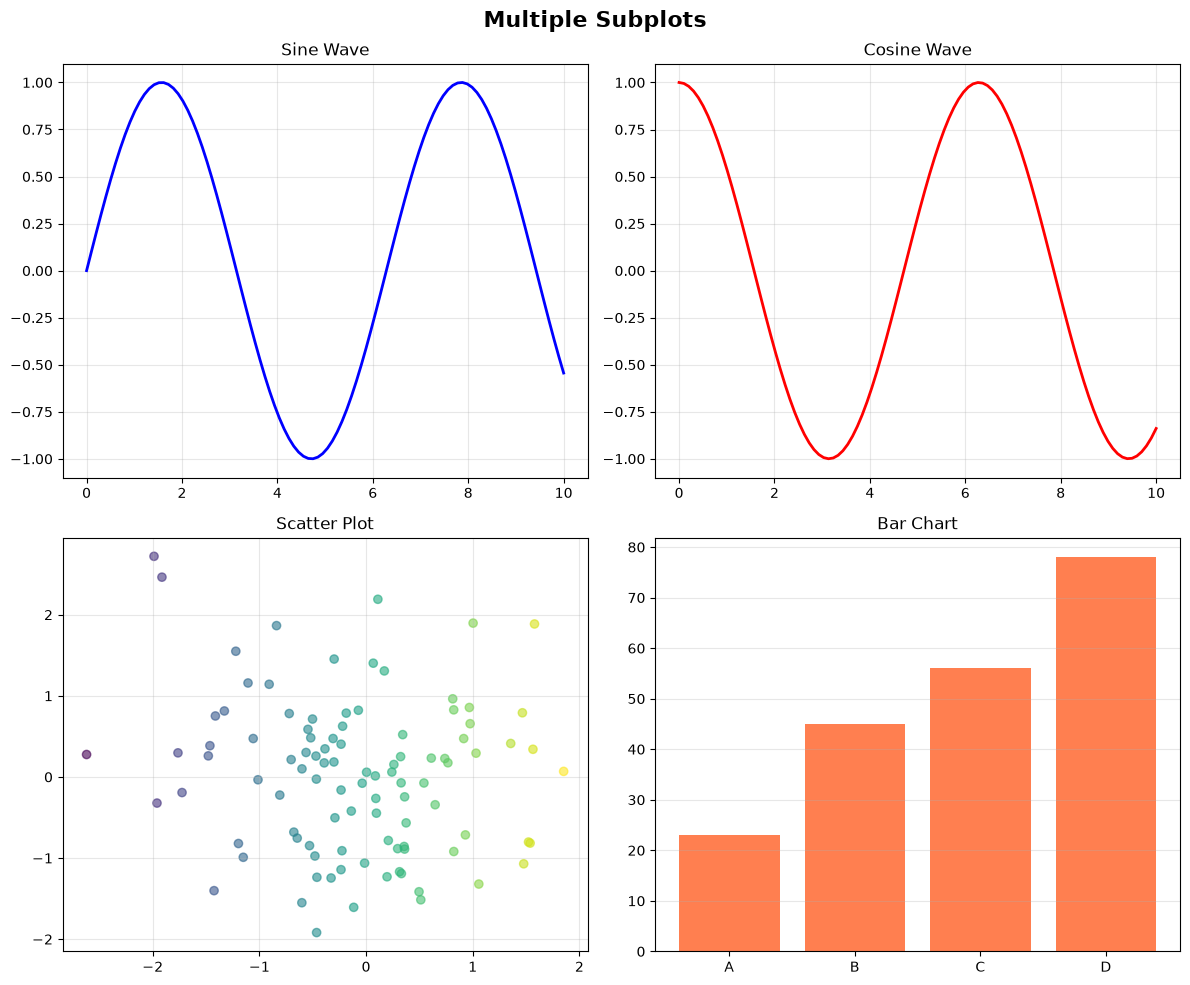

In [58]:
# Create 2x2 subplot grid
x = np.linspace(0, 10, 100)

fig, axes = plt.subplots(2, 2, figsize=(12, 10)) # Passes the number of rows and columns of subplots that are desired
fig.suptitle("Multiple Subplots", fontsize=16, fontweight="bold")

# Top left: Line plot
axes[0, 0].plot(x, np.sin(x), "b-", linewidth=2)
axes[0, 0].set_title("Sine Wave")
axes[0,0].grid(True, alpha=0.3)

# Top right: Cosine
axes[0, 1].plot(x, np.cos(x), "r-", linewidth=2)
axes[0, 1].set_title("Cosine Wave")
axes[0, 1].grid(True, alpha=0.3)

# Bottom left: Scatter
np.random.seed(42)
x_scatter = np.random.randn(100)
y_scatter = np.random.randn(100)
axes[1, 0].scatter(x_scatter, y_scatter, alpha=0.6, c=x_scatter, cmap="viridis")
axes[1, 0].set_title("Scatter Plot")
axes[1, 0].grid(True, alpha=0.3)

# Bottom right: Bar chart
categories = ["A", "B", "C", "D"]
values = [23, 45, 56, 78]
axes[1, 1].bar(categories, values, color="coral")
axes[1, 1].set_title("Bar Chart")
axes[1, 1].grid(True, alpha=0.3, axis="y")

plt.tight_layout() # Collates the 4 subplots together and adjusts spacing between them
plt.show()

## 8. Working with Pandas DataFrames
Matplotlib integrates seamlessly with Pandas, making it easy to plot data directly from DataFrames

In [59]:
# Create a sample DataFrame
np.random.seed(42)
dates = pd.date_range("2023-01-01", periods=100, freq="D")
df = pd.DataFrame({
    "Date": dates,
    "Sales": np.random.randint(1000, 5000, 100) + np.sin(np.arange(100))*500,
    "Profit": np.random.randint(200, 800, 100) + np.cos(np.arange(100))*200,
    "Region": np.random.choice(["North", "South", "East", "West"], 100)
})

print(f"Sample DataFrame:\n{df.head()}\nDataFrame shape: {df.shape}")

Sample DataFrame:
        Date        Sales      Profit Region
0 2023-01-01  4174.000000  801.000000  South
1 2023-01-02  4927.735492  863.060461   East
2 2023-01-03  2314.648713  277.770633  South
3 2023-01-04  2364.560004  203.001501   East
4 2023-01-05  1751.598752  338.271276  North
DataFrame shape: (100, 4)


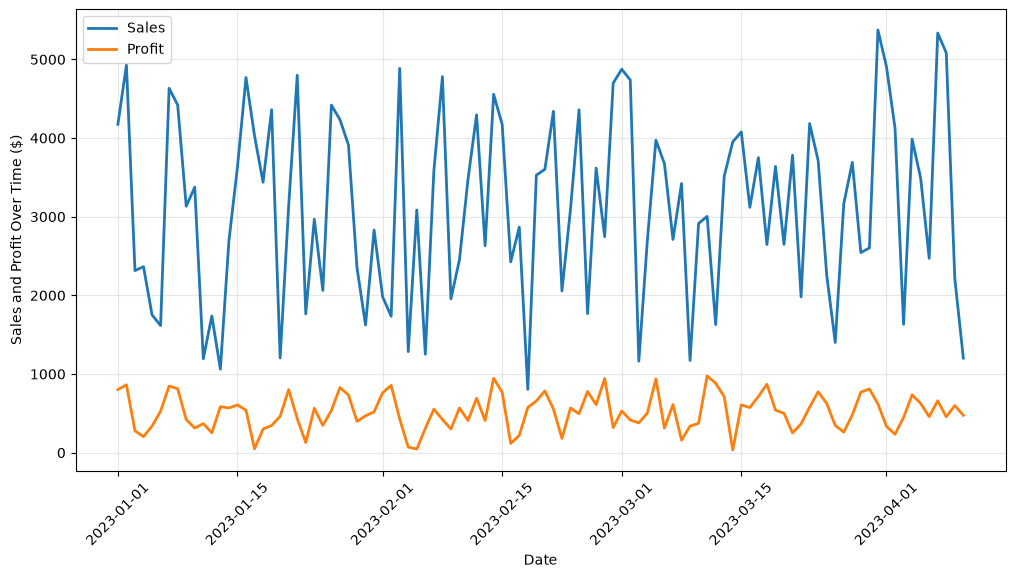

In [60]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df["Date"], df["Sales"], label="Sales", linewidth=2)
ax.plot(df["Date"], df["Profit"], label="Profit", linewidth=2)
ax.set_xlabel("Date")
ax.set_ylabel("Sales and Profit Over Time ($)")
ax.legend()
ax.grid(True, alpha=0.3)
ax.tick_params(axis="x", rotation=45) # Rotate x-axis labels. If using OOP approach, then must use "ax.tick_params" and specify the x axis
# plt.xticks(rotation=45) - Alternatively, if not using OOP approach, use this line
plt.show()

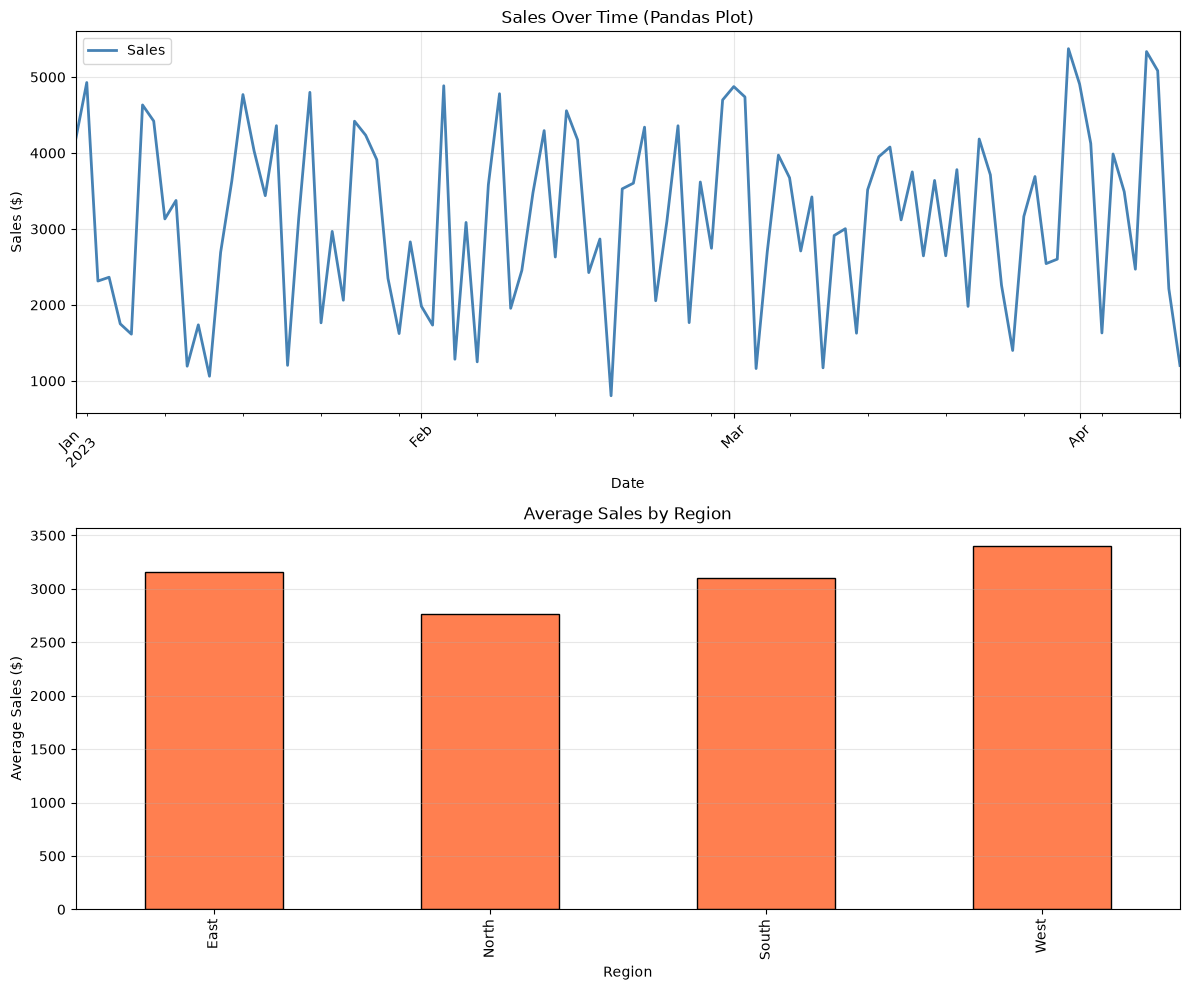

In [61]:
# Using Pandas plot method(even simpler)
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Plot using Pandas .plot() method
df.plot(x="Date", y="Sales", ax=axes[0], color="steelblue", linewidth=2)
axes[0].set_title("Sales Over Time (Pandas Plot)", fontsize=12)
axes[0].set_ylabel("Sales ($)")
axes[0].grid(True, alpha=0.3)
axes[0].tick_params(axis="x", rotation=45)

# Bar chart by region
region_sales = df.groupby("Region")["Sales"].mean()
region_sales.plot(kind="bar", ax=axes[1], color="coral", edgecolor="black")
axes[1].set_title("Average Sales by Region", fontsize=12)
axes[1].set_ylabel("Average Sales ($)")
axes[1].set_xlabel("Region")
axes[1].grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

## 9. Advanced Customisation: Annotations, Text, and Legends
Adding annotations and customising text elements can make your plots more informative and professional.

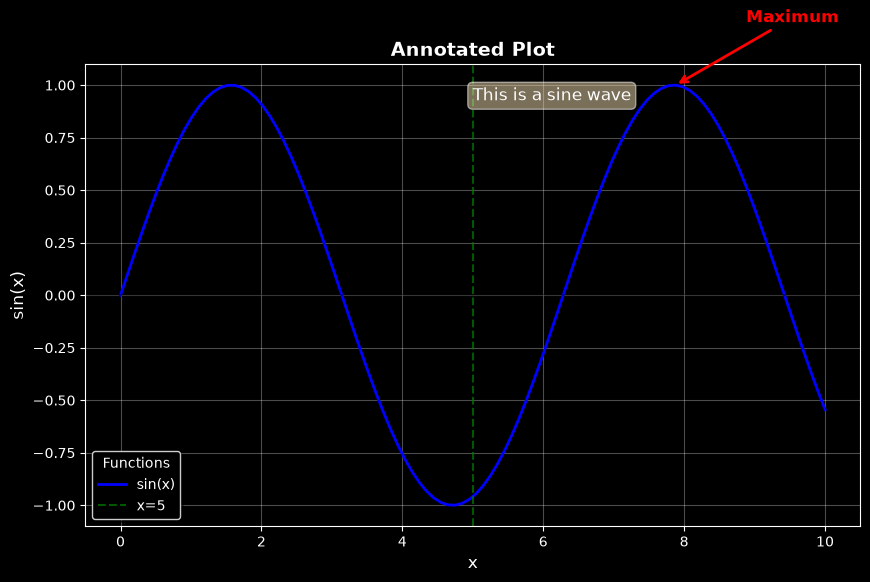

In [71]:
x = np.linspace(0, 10, 100)
y = np.sin(x)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(
    x, y,
    "b-",
    linewidth=2,
    label="sin(x)"
)

# Add text annotation
max_idx = np.argmax(y) # Looks at the maximum y value in order to annotate it as a maximum
# Here, "xy" is the postion where the anotation should be and "xytext" sets where the annotation should be relative to where the arrow should end
ax.annotate(
    "Maximum",
    xy=(x[max_idx], y[max_idx]),
        xytext=(x[max_idx]+1, y[max_idx]+0.3),
        arrowprops=dict[str, Any](arrowstyle="->", color="red", lw=2),
        fontsize=12, color="red", fontweight="bold"
)

# Add text box
ax.text(
    0.5, 0.95,
    "This is a sine wave",
    fontsize=12,
    transform=ax.transAxes,
    verticalalignment="top",
    bbox=dict[str, str | float](# "bbox" draws a box around the given text
        boxstyle="round", # "transform=ax.transAxes" interprets the coordinates as axes coordinates, not data coordinates
        facecolor="wheat",
        alpha=0.5)
)

# Add vertical and horizontal lines
ax.axvline(
    x=5,
    color="green",
    linestyle="--",
    alpha=0.7,
    label="x=5"
)
ax.axhline(
    y=0,
    color="black",
    linestyle="-",
    alpha=0.3
)

# Customise legend
ax.legend(
    loc="best",
    frameon=True,
    fancybox=True,
    shadow=True,
    fontsize=10,
    title="Functions"
)

ax.set_xlabel("x", fontsize=12)
ax.set_ylabel("sin(x)", fontsize=12)
ax.set_title("Annotated Plot", fontsize=14, fontweight="bold")
ax.grid(True, alpha=0.3)
plt.show()

## 10. Plot Styles and Themes
Matplotlib comes with several built-in styles that can instantly change the appearance of the plots.

In [69]:
# Available styles
print(f"Available Matplotlib styles:\n{plt.style.available}")

Available Matplotlib styles:
['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


## 11. Pie Charts

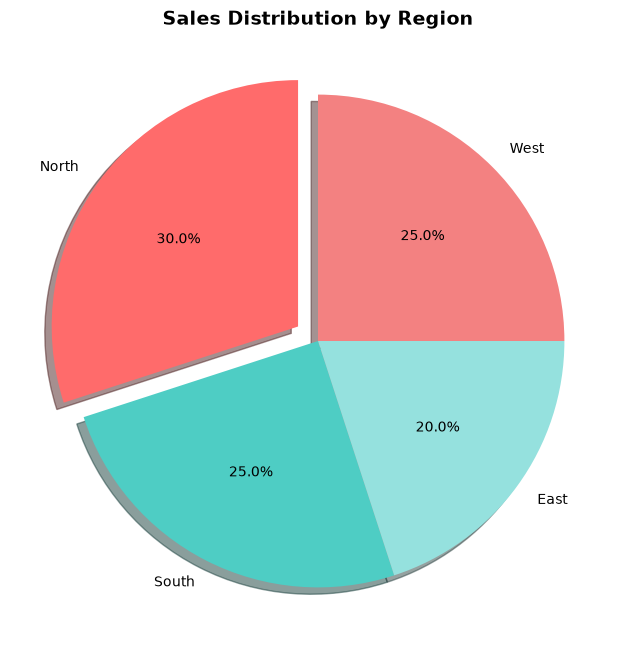

In [ ]:
# Simple pie chart
categories = ["North", "South", "East", "West"]
sizes = [30, 25, 20, 25]
colours = ["#FF6B6B", "#4ECDC4", "#95E1DE", "#F38181"]
explode = (0.1, 0, 0, 0) # Explode the first slice

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    sizes,
    explode=explode,
    labels=categories,
    colors=colours,
    autopct="%1.1f%%",
    shadow=True,
    startangle=90
)
ax.set_title(
    "Sales Distribution by Region",
    fontsize=14,
    fontweight="bold"
)
plt.show()

# Can also save as PNG (raster), PDF (vector), SVG (vector), EPS (vector)
# fig.savefig("myplot.pdf", bbox_inches="tight") - can use facecolor here for the background colour